# Exercise 1: A function to compute average grades

In this series of exercises, we will use LLMs to generate code based on specific requirements and then compare the output against predefined test cases to ensure correctness. The focus will be on generating functional code and executing tests to verify that it meets the given specifications.

### Step 1: Requirements

The function receives the grades of a student on her courses (for simplicity exactly six grades for six courses are considered) and computes the average. Grades can be from 18 to 30, or 30Laude (which is represented by the int number 33). The average is computed excluding the best and worse grade.
The first comparison source is generated by this Codex agent during this solving session and labeled **Codex**. No external ChatGPT response is invented. Grades 31 and 32 are invalid; 33 denotes laude. The supplied tests are retained unchanged, including their loose tolerance.


In [1]:
def compute_average(grades):
    """Trim one minimum and maximum from six valid grades; do not mutate input."""
    from numbers import Real
    import math
    if not isinstance(grades, (list, tuple)) or len(grades) != 6:
        raise ValueError("Exactly six grades are required")
    for grade in grades:
        if isinstance(grade, bool):
            raise ValueError("Boolean values are not grades")
        if not isinstance(grade, Real):
            raise TypeError("Grades must be real numbers")
        if not math.isfinite(grade) or not (18 <= grade <= 30 or grade == 33):
            raise ValueError("Grades must be between 18 and 30, or 33 for laude")
    return sum(sorted(grades)[1:-1]) / 4

from pathlib import Path
import json

print(f"The computed average is: {compute_average([18,25,30,33,22,28]):.2f}")
# Fresh code authored by this Codex agent in this session, not a captured ChatGPT UI response.
# Preserve provenance rather than falsely labeling this as an external GPT run.
codex_result = 'def compute_average(grades):\n    """Return the trimmed mean of six grades, with 33 representing laude."""\n    import math\n    from numbers import Real\n    if not isinstance(grades, (list, tuple)) or len(grades) != 6:\n        raise ValueError("Expected exactly six grades")\n    for value in grades:\n        if isinstance(value, bool):\n            raise ValueError("A boolean is not a grade")\n        if not isinstance(value, Real):\n            raise TypeError("Expected numeric grades")\n        if not math.isfinite(value) or not (18 <= value <= 30 or value == 33):\n            raise ValueError("Invalid grade")\n    return (sum(grades) - min(grades) - max(grades)) / 4\n'
my_codes = {"Codex": codex_result}
code_provenance = {"Codex": "Fresh Codex-generated baseline from this solving session"}
Path("function_01.py").write_text(codex_result)
print(code_provenance)

sys_prompt = "You are a Python programmer. Return only valid Python source, without Markdown fences or explanations."
query = """Implement compute_average(grades). Require exactly six grades; accept real values from 18 to 30 inclusive or 33 for laude. Reject booleans/invalid values with ValueError and nonnumeric values with TypeError. Return the arithmetic mean after removing exactly one minimum and one maximum. Do not mutate the input."""


The computed average is: 26.25
{'Codex': 'Fresh Codex-generated baseline from this solving session'}


### Step 2: Test Cases

To generate a comprehensive black-box test suite for the compute_average function, we will create tests that cover different equivalence classes, boundary conditions, and typical scenarios.

- Valid inputs: 
  - Standard valid grades within the range of 18 to 33, including "30Laude" (33).
  - Tests where all grades are different, with some being 30Laude.

- Boundary values:
  - Input with the lowest valid grade (18) and the highest valid grade (33).

- Invalid inputs:
  - A grade list that has more or fewer than 6 grades.
  - Grades outside the valid range (less than 18 or greater than 33).
  - non-numeric inputs

- Edge cases:
  - All grades are the same.
  - All grades are 30Laude (33).


In [2]:
import pytest

@pytest.mark.parametrize("grades, expected", [
    ([18,25,30,33,22,28],26.25),
    ([20,25,30,33,29,28],28.0),
    ([18,19,20,30,33,25],23.5),
    ([18]*6,18.0), ([30]*6,30.0), ([33]*6,33.0),
    ([25]*6,25.0), ([18,18,18,33,33,33],25.5),
    ([18.5,20,22,24,26,30],23.0),
])
def test_valid_grades(grades, expected):
    original = grades.copy()
    assert compute_average(grades) == pytest.approx(expected, abs=1e-10)
    assert grades == original

@pytest.mark.parametrize("grades", [[18]*5,[18]*7,[],[17,20,22,24,26,30],
    [34,20,22,24,26,30],[31,20,22,24,26,30],[32,20,22,24,26,30],
    [float("nan"),20,22,24,26,30],[float("inf"),20,22,24,26,30],
    [True,20,22,24,26,30]])
def test_invalid_grades(grades):
    with pytest.raises(ValueError): compute_average(grades)

@pytest.mark.parametrize("value", ["25",None,complex(25,0)])
def test_non_numeric_grades(value):
    with pytest.raises(TypeError): compute_average([value,20,22,24,26,30])


### Step 3: Run the test cases

This code defines a function run_tests that uses the ipytest library to run test cases within a Jupyter notebook. The ipytest library seeks for test cases in the notebook and launches them. The '-vv' parameter is used to provide a verbose output.

In [3]:
import ipytest
ipytest.autoconfig()
# A clean notebook test module, independent of test files used for model comparison.
reference_exit_code = ipytest.run("-vv")
if int(reference_exit_code) != 0:
    raise RuntimeError("Reference tests failed; fix the reference before comparing generated code")
print("All notebook reference boundary/validation tests passed.")
print("Supplied test_valid_grades_with_30laude expects 27.75 with 1% tolerance; exact answer is 28.0.")
print("The supplied test file is preserved; strict tests above check the exact result.")


======================================= test session starts ========================================
platform darwin -- Python 3.11.16, pytest-9.1.1, pluggy-1.7.0 -- /Users/nicolabeccaceci/.venvs/llms-lab09/bin/python
cachedir: .pytest_cache
rootdir: /Users/nicolabeccaceci/Desktop/LLMs/LABS/lab09
plugins: platformdirs-4.13.5
collecting ... 

collected 22 items

t_de183bbd677e46caace029b07ed9ee5e.py::test_valid_grades[grades0-26.25] 

PASSED               [  4%]


t_de183bbd677e46caace029b07ed9ee5e.py::test_valid_grades[grades1-28.0] 

PASSED                [  9%]

...


t_de183bbd677e46caace029b07ed9ee5e.py::test_non_numeric_grades[None] 

PASSED                  [ 95%]


t_de183bbd677e46caace029b07ed9ee5e.py::test_non_numeric_grades[(25+0j)] 

PASSED               [100%]



======================================== 22 passed in 0.04s ========================================
All notebook reference boundary/validation tests passed.
Supplied test_valid_grades_with_30laude expects 27.75 with 1% tolerance; exact answer is 28.0.
The supplied test file is preserved; strict tests above check the exact result.


### Step 4: Generating code with Llama 3.2

In this step, we leverage Llama 3.2 to automatically generate Python code based on specified requirements.

In this step, we define a prompt for coding by providing the requirements, the arguments, and the expected returns.


In [4]:
import gc
import torch
from huggingface_hub import get_token
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed

set_seed(42)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Using device:", device)
model = tokenizer = None
current_model_id = None

def select_engine(model_id):
    """Hold one model at a time so comparisons fit the local memory budget."""
    global model, tokenizer, current_model_id
    if current_model_id == model_id and model is not None:
        return
    model = tokenizer = None
    current_model_id = None
    gc.collect()
    if device == "mps": torch.mps.empty_cache()
    if device == "cuda": torch.cuda.empty_cache()
    dtype = torch.float16 if device != "cpu" else torch.float32
    model = AutoModelForCausalLM.from_pretrained(
        model_id, torch_dtype=dtype, low_cpu_mem_usage=True,
        token=get_token(),
    ).to(device).eval()
    tokenizer = AutoTokenizer.from_pretrained(model_id, token=get_token())
    tokenizer.pad_token = tokenizer.eos_token
    current_model_id = model_id

def make_a_query(prompt, tokenizer, model, device, max_new_tokens=768):
    inputs = tokenizer(prompt, return_tensors="pt", add_special_tokens=False).to(device)
    with torch.inference_mode():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens,
            do_sample=False, pad_token_id=tokenizer.eos_token_id)
    return tokenizer.decode(output[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()

# The supplied checkpoint is Llama 3.2, despite the original heading saying CodeLlama.
model_id = "meta-llama/Llama-3.2-3B-Instruct"
select_engine(model_id)


/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using device: mps


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:  50%|█████     | 1/2 [00:12<00:12, 12.47s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  7.30s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:16<00:00,  8.07s/it]

In [5]:
sys_prompt = "You are a Python programmer. Return only valid Python source, without Markdown fences or explanations."
query = """Implement compute_average(grades). Require exactly six grades; accept real values from 18 to 30 inclusive or 33 for laude. Reject booleans/invalid values with ValueError and nonnumeric values with TypeError. Return the arithmetic mean after removing exactly one minimum and one maximum. Do not mutate the input."""
prompt = tokenizer.apply_chat_template([
    {"role":"system","content":sys_prompt},
    {"role":"user","content":query},
], tokenize=False, add_generation_prompt=True)
generated_code = make_a_query(prompt, tokenizer, model, device)
# Remove only an enclosing Markdown code fence if the instruction was not followed.
if generated_code.startswith("```"):
    generated_code = generated_code.split("\n",1)[1].rsplit("```",1)[0].strip()
my_codes["Llama-3.2-3B-Instruct"] = generated_code
code_provenance["Llama-3.2-3B-Instruct"] = current_model_id
print(generated_code)


/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


def compute_average(grades):
    """
    Compute the arithmetic mean of a list of grades after removing the minimum and maximum values.

    Args:
        grades (list): A list of grades. Each grade should be a real number between 18 and 30 inclusive or 33 for laude.

    Returns:
        float: The arithmetic mean of the remaining grades.

    Raises:
        ValueError: If the list contains booleans, invalid values, or nonnumeric values.
        TypeError: If the input is not a list.
    """

    # Check if input is a list
    if not isinstance(grades, list):
        raise TypeError("Input must be a list")

    # Check if list contains booleans or invalid values
    if not all(isinstance(grade, (int, float)) and 18 <= grade <= 30 or grade == 33 for grade in grades):
        raise ValueError("List must contain only real numbers between 18 and 30 inclusive or 33 for laude")

    # Create a copy of the list to avoid mutation
    grades_copy = grades.copy()

    # Remove the minimum and 

### Step 5: organizing and analyzing test case results with pytest

The code automates the process of running test cases in a Python file using pytest and parsing the results. It defines a function, parse_test_results, that extracts the counts of errors, failures, and passes from a summary line of the pytest output using regular expressions. The script runs the specified test file (test_cases_01.py) via a subprocess call to pytest, capturing its output in plain text. From the output, it locates the summary line containing test results and uses the parse_test_results function to extract key metrics. It calculates the functional correctness ratio as the fraction of passed tests to the total number of tests executed and prints the counts of passed, failed, and errored tests, along with the computed functional correctness ratio. This process provides a clear and automated way to assess the reliability of the tested code.

In [6]:
import hashlib
import re
import shutil
import subprocess
import sys
import tempfile
import xml.etree.ElementTree as ET
from pathlib import Path

def parse_test_results(result_string):
    def count(pattern):
        match = re.search(pattern, result_string)
        return int(match.group(1)) if match else 0
    return count(r"(\d+)\s+errors?"), count(r"(\d+)\s+failed"), count(r"(\d+)\s+passed")

def evaluate_code(code, test_file="test_cases_01.py", function_file="function_01.py", name="generated"):
    # Each subprocess gets a fresh import directory; no model can inherit the prior code's bytecode.
    evidence = Path("execution") / "evaluations" / re.sub(r"[^A-Za-z0-9_.-]", "_", name)
    evidence.mkdir(parents=True, exist_ok=True)
    with tempfile.TemporaryDirectory(prefix="lab09-tests-") as temporary:
        run_dir = Path(temporary)
        (run_dir/function_file).write_text(code)
        shutil.copy2(test_file, run_dir/Path(test_file).name)
        result = subprocess.run([sys.executable,"-m","pytest",Path(test_file).name,
            "-q","--disable-warnings","--tb=short","--color=no","--junitxml=report.xml"],
            cwd=run_dir, capture_output=True, text=True, timeout=60)
        (evidence/"stdout.txt").write_text(result.stdout+result.stderr)
        report = run_dir/"report.xml"
        if not report.exists(): raise RuntimeError("pytest produced no test report: "+result.stderr)
        shutil.copy2(report,evidence/"junit.xml")
        cases = ET.parse(report).getroot().findall(".//testcase")
        failures = sum(case.find("failure") is not None for case in cases)
        errors = sum(case.find("error") is not None for case in cases)
        skipped = sum(case.find("skipped") is not None for case in cases)
        passes = len(cases)-failures-errors-skipped
        total = passes+failures+errors
        if total == 0: raise RuntimeError("No tests ran")
        metrics = {"Passed":passes,"Failed":failures,"Errors":errors,"Skipped":skipped,
            "FunctionalCorrectness":passes/total,"pytest_exit_code":result.returncode,
            "SourceSHA256":hashlib.sha256(code.encode()).hexdigest()}
        (evidence/"metrics.json").write_text(json.dumps(metrics,indent=2))
        print(name,metrics)
        return metrics

codex_metrics = evaluate_code(my_codes["Codex"],name="Codex_grades")
codex_functional_correctness = codex_metrics["FunctionalCorrectness"]


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Codex_grades {'Passed': 14, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': '42d51761595f164133f1f4ef76c696cfab648dae72a55d2c2d8b3121030b8462'}


### Step 6: comparing results

We now extend our analysis to compare the results provided by different agents.

For simplicity, we store the function always on the same file (e.g., function_01.py) and we re-execute the same test file (e.g., test_cases_01.py)

We evaluate the results based on the functional correctness ratio, and we select the best option that was generated.

In [7]:
llama_label = "Llama-3.2-3B-Instruct"
llama_metrics = evaluate_code(my_codes[llama_label],name="Llama_grades")
llama_functional_correctness = llama_metrics["FunctionalCorrectness"]


Llama_grades {'Passed': 9, 'Failed': 5, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.6428571428571429, 'pytest_exit_code': 1, 'SourceSHA256': '71df77699c59cf835031a0116601738837086882f18d4b502d6fab131bffe79a'}


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


### Step 7: Analyzing and comparing the quality of the generated code

Static code quality metrics are used to evaluate the structure, readability, and maintainability of code without executing it. Below is a Python program that calculates some common static code quality metrics for a given Python file:

- Lines of Code (LOC): The total number of lines in the file.
- Comment Density: The percentage of lines that are comments.
- Cyclomatic Complexity: A measure of the complexity of a program based on the number of linearly independent paths.
- Maintainability Index (MI): a software metric used to predict how maintainable the code is. It’s often calculated using a combination of Cyclomatic Complexity (CC), Lines of Code (LOC), and Halstead Volume (HV).

The **Radon** tool is a Python package that helps analyze various aspects of code quality, such as Cyclomatic Complexity (CC), Maintainability Index (MI), Raw Metrics (LOC), and Halstead metrics. You can use Radon to analyze the static code quality of your Python code by running it from the command line or through Python code.

The tool can be installed by the following command: pip install radon


In [8]:
import radon.complexity as radon_complexity
import radon.metrics as radon_metrics
import radon.raw as radon_raw

def analyze_code_with_radon(file_path):
    code = Path(file_path).read_text()
    functions = radon_complexity.cc_visit(code)
    raw = radon_raw.analyze(code)
    return {"CC":max((block.complexity for block in functions),default=0),
        "MI":radon_metrics.mi_visit(code,multi=False),"LOC":raw.loc,
        "Comments":raw.comments}

def compare_codes(codes, test_file="test_cases_01.py", function_file="function_01.py", suffix="grades"):
    results = {}
    for name, code in codes.items():
        # Export each exact observed source, then measure the same source.
        source_path = Path("execution")/"sources"/(re.sub(r"[^A-Za-z0-9_.-]","_",name)+"_"+suffix+".py")
        source_path.parent.mkdir(parents=True,exist_ok=True)
        source_path.write_text(code)
        static = analyze_code_with_radon(source_path)
        dynamic = evaluate_code(code,test_file,function_file,name+"_"+suffix)
        results[name] = {**static,**dynamic}
    return results

overall_results = compare_codes(my_codes)
print(json.dumps(overall_results,indent=2))
print("Only actually generated sources are included:",code_provenance)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Codex_grades {'Passed': 14, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': '42d51761595f164133f1f4ef76c696cfab648dae72a55d2c2d8b3121030b8462'}


Llama-3.2-3B-Instruct_grades {'Passed': 9, 'Failed': 5, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.6428571428571429, 'pytest_exit_code': 1, 'SourceSHA256': '71df77699c59cf835031a0116601738837086882f18d4b502d6fab131bffe79a'}
{
  "Codex": {
    "CC": 9,
    "MI": 58.00073622123373,
    "LOC": 14,
    "Comments": 0,
    "Passed": 14,
    "Failed": 0,
    "Errors": 0,
    "Skipped": 0,
    "FunctionalCorrectness": 1.0,
    "pytest_exit_code": 0,
    "SourceSHA256": "42d51761595f164133f1f4ef76c696cfab648dae72a55d2c2d8b3121030b8462"
  },
  "Llama-3.2-3B-Instruct": {
    "CC": 7,
    "MI": 89.72051787423352,
    "LOC": 38,
    "Comments": 6,
    "Passed": 9,
    "Failed": 5,
    "Errors": 0,
    "Skipped": 0,
    "FunctionalCorrectness": 0.6428571428571429,
    "pytest_exit_code": 1,
    "SourceSHA256": "71df77699c59cf835031a0116601738837086882f18d4b502d6fab131bffe79a"
  }
}
Only actually generated sources are included: {'Codex': 'Fresh Codex-generated baseline from this solving se

### Step 8: Plotting the results

generate a set of bar charts to visualize various software metrics for different programming languages, including Cyclomatic Complexity (CC), Maintainability Index (MI), Lines of Code (LOC), and the number of comments. 

start by extracting the relevant data from the overall_results dictionary, which contains these metrics for each language. Then, using Matplotlib, create a 3x2 grid of subplots, each one dedicated to a different metric. 

The first four subplots display the values for CC, MI, LOC, and comments, while the last subplot shows the functional correctness values for two models, GPT and LLaMA. 

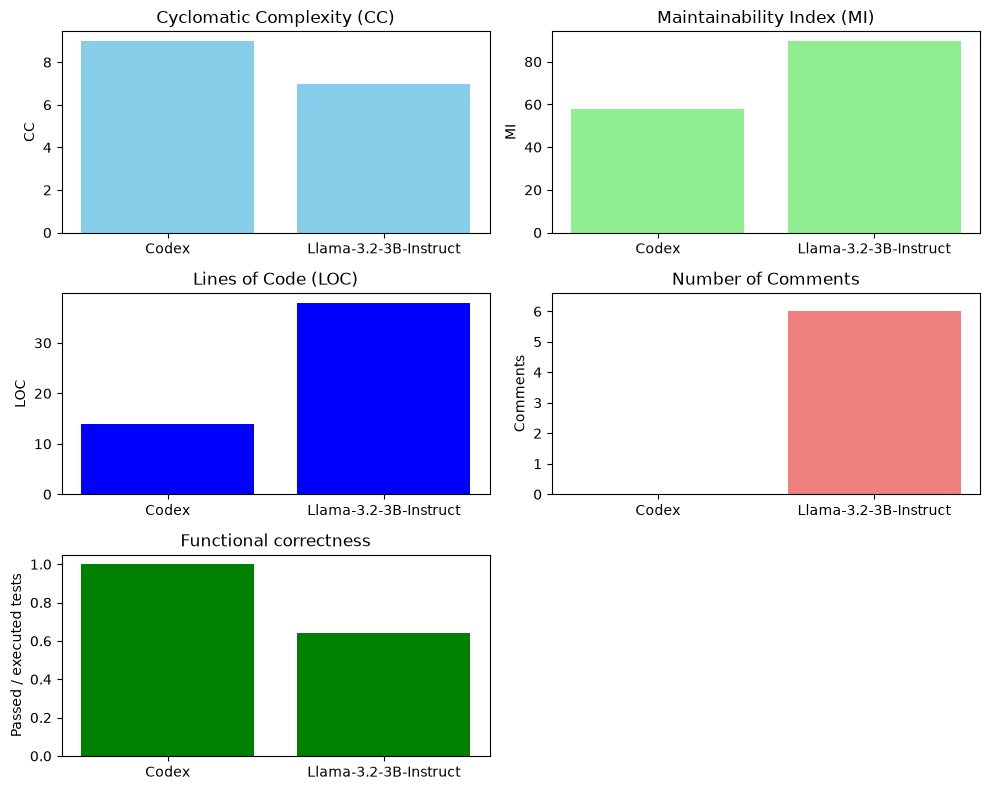

In [9]:
import matplotlib.pyplot as plt
import numpy as np


languages = list(overall_results.keys())  



cc_values = [overall_results[language]['CC'] for language in languages]
mi_values = [overall_results[language]['MI'] for language in languages]
loc_values = [overall_results[language]['LOC'] for language in languages]
comments_values = [overall_results[language]['Comments'] for language in languages]
functional_correctness = [overall_results[language]['FunctionalCorrectness'] for language in languages]

# Create a figure with subplots for each metric
fig, axs = plt.subplots(3, 2, figsize=(10, 8))

# Plotting CC values
axs[0, 0].bar(languages, cc_values, color='skyblue')
axs[0, 0].set_title('Cyclomatic Complexity (CC)')
axs[0, 0].set_ylabel('CC')

# Plotting MI values
axs[0, 1].bar(languages, mi_values, color='lightgreen')
axs[0, 1].set_title('Maintainability Index (MI)')
axs[0, 1].set_ylabel('MI')

# Plotting LOC values
axs[1, 0].bar(languages, loc_values, color='blue')
axs[1, 0].set_title('Lines of Code (LOC)')
axs[1, 0].set_ylabel('LOC')

# Plotting Comments values
axs[1, 1].bar(languages, comments_values, color='lightcoral')
axs[1, 1].set_title('Number of Comments')
axs[1, 1].set_ylabel('Comments')
axs[1, 1].set_ylim(0, max(comments_values + [1]) * 1.1)

#plotting functional correctness
axs[2, 0].bar(languages, functional_correctness, color='green')
axs[2, 0].set_title('Functional correctness')
axs[2, 0].set_ylabel('Passed / executed tests')
axs[2, 0].set_ylim(0, 1.05)
axs[2, 1].axis('off')

# Adjust layout and display the plot
plt.tight_layout()
Path("execution/figures").mkdir(parents=True,exist_ok=True)
fig.savefig("execution/figures/grade_code_metrics.png",dpi=160,bbox_inches="tight")
plt.show()


# Exercise 2: Comparing more LLM agents

After analyzing a chat engine (GPT) and a HuggingFace model (CodeLLAMA) try to generate additional examples of code with other engines.

You can use to this purpose other models provided by HuggingFace, and/or other ready-made chat engines (e.g., Qwen).
NOTE: choose the *-Instruct version to be able to use chat template; otherwise, refer to the model's Hugging Face pace for prompting syntax

In [10]:
# A separate additional-engine comparison, not a replacement for the specified Llama model.
# Run this when a heavy-compute slot is available; it downloads the named public checkpoint.
additional_model_id = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
select_engine(additional_model_id)
additional_prompt = tokenizer.apply_chat_template([
    {"role":"system","content":sys_prompt},{"role":"user","content":query},
], tokenize=False, add_generation_prompt=True)
qwen_chat = make_a_query(additional_prompt,tokenizer,model,device)
if qwen_chat.startswith("```"):
    qwen_chat = qwen_chat.split("\n",1)[1].rsplit("```",1)[0].strip()
my_codes["Qwen2.5-Coder-1.5B-Instruct"] = qwen_chat
code_provenance["Qwen2.5-Coder-1.5B-Instruct"] = additional_model_id
print(qwen_chat)
overall_results = compare_codes(my_codes)
print(json.dumps(overall_results,indent=2))


/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.7` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.8` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(
/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:612: UserWarning: `do_sample` is set to `False`. However, `top_k` is set to `20` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_k`.
  warnings.warn(


def compute_average(grades):
    if len(grades) != 6:
        raise ValueError("Exactly six grades are required.")
    
    grades = [grade for grade in grades if isinstance(grade, (int, float)) and 18 <= grade <= 30 or grade == 33]
    if len(grades) < 5:
        raise ValueError("At least five grades are required after filtering.")
    
    min_val = min(grades)
    max_val = max(grades)
    grades.remove(min_val)
    grades.remove(max_val)
    
    return sum(grades) / len(grades)


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Codex_grades {'Passed': 14, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': '42d51761595f164133f1f4ef76c696cfab648dae72a55d2c2d8b3121030b8462'}


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Llama-3.2-3B-Instruct_grades {'Passed': 9, 'Failed': 5, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.6428571428571429, 'pytest_exit_code': 1, 'SourceSHA256': '71df77699c59cf835031a0116601738837086882f18d4b502d6fab131bffe79a'}


Qwen2.5-Coder-1.5B-Instruct_grades {'Passed': 8, 'Failed': 6, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.5714285714285714, 'pytest_exit_code': 1, 'SourceSHA256': '41c70d817e176461bff36f9832cc21ab5a592899a3461532fd320a4f32ac2ce4'}
{
  "Codex": {
    "CC": 9,
    "MI": 58.00073622123373,
    "LOC": 14,
    "Comments": 0,
    "Passed": 14,
    "Failed": 0,
    "Errors": 0,
    "Skipped": 0,
    "FunctionalCorrectness": 1.0,
    "pytest_exit_code": 0,
    "SourceSHA256": "42d51761595f164133f1f4ef76c696cfab648dae72a55d2c2d8b3121030b8462"
  },
  "Llama-3.2-3B-Instruct": {
    "CC": 7,
    "MI": 89.72051787423352,
    "LOC": 38,
    "Comments": 6,
    "Passed": 9,
    "Failed": 5,
    "Errors": 0,
    "Skipped": 0,
    "FunctionalCorrectness": 0.6428571428571429,
    "pytest_exit_code": 1,
    "SourceSHA256": "71df77699c59cf835031a0116601738837086882f18d4b502d6fab131bffe79a"
  },
  "Qwen2.5-Coder-1.5B-Instruct": {
    "CC": 7,
    "MI": 62.30659087147264,
    "LOC": 14,
    "Commen

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


# Exercise 3: Additional functions

To evaluate the generalizability of the LLM code generation, now modify the functions on which you are applying your analysis.

Consider the following requirements:

### Railway company

A railway company offers the possibility to people under 15 to travel free. The offer is dedicated to groups
from 2 to 5 people travelling together.
For being eligible to the offer, at least a member of the group must be at least 18 years old. If this condition
applies, all the under 15 members of the group travel free, and the others pay the Base Price.
The function computeFee receives as parameters basePrice (the price of the ticket), n_passengers (the
number of passengers of the group), n_over18 (the number of passengers at least 18 old), n_under15 (the
number of passengers under 15 years old). It gives as output the amount that the whole group has to spend. It
gives an error if groups are composed of more than 5 persons.
double computeFee(double basePrice, int n_passengers, int n_over18, int n_under15);

- define test cases for this case study in test_cases_02.py
- use a file function_02.py to host the generated results for this function

### Bike Race

In a bike race, the bikers must complete the entire track within a maximum time, otherwise their race is not
valid. The maximum time is computed, for each race, based on the winner's time, on the average speed on the
track, and on the category of the track.
For tracks of category 'A' (easy tracks) the maximum time is computed as the winner's time increased by 5% if
the average speed is lower than 30 km/h (30 included), 10% if the average speed is between 30 and 35 km/h (35
included), and 15% if the average speed is higher than 35 km/h.
For tracks of category 'B' (normal tracks) the maximum time is computed as the winner's time increased by 20%
if the average speed is lower than 30 km/h (30 included), 25% if the average speed is between 30 and 35 km/h
(35 included), and 30% if the average speed is higher than 35 km/h.
For tracks of category 'C' (hard tracks) the maximum time does not depend on average speed, and is always
computed as the winner's time increased by 50%.
The function computeMaxTime receives as parameters winner_time (the time of the winner, in minutes),
avg_speed (the average speed of the track, in km/h) and track_type (a char, whose valid values are 'A', 'B', or
'C'). It gives as output the maximum time, 0 if there are errors in the input.
double computeMaxTime(double winner_time, double avg_speed, char track_type)

- define test cases for this case study in test_cases_03.py
- use a file function_03.py to host the generated results for this function

Re-execute the analysis once you have your test cases and adapted prompts. What changes baed on the complexity of the requirements to implement?



In [11]:
# Fresh Codex-generated source and black-box tests for the two additional requirements.
# These are genuine local agent outputs; Llama/Qwen comparison requires actual generation below.
fee_source = 'def computeFee(basePrice, n_passengers, n_over18, n_under15):\n    from numbers import Real\n    import math\n    if isinstance(basePrice,bool) or not isinstance(basePrice,Real) or not math.isfinite(basePrice) or basePrice < 0:\n        raise ValueError("Invalid base price")\n    counts = (n_passengers,n_over18,n_under15)\n    if any(isinstance(n,bool) or not isinstance(n,int) for n in counts):\n        raise ValueError("Passenger counts must be integers")\n    if not 1 <= n_passengers <= 5 or min(n_over18,n_under15) < 0 or n_over18+n_under15 > n_passengers:\n        raise ValueError("Inconsistent group counts")\n    eligible = n_passengers >= 2 and n_over18 >= 1\n    return float(basePrice * (n_passengers-n_under15 if eligible else n_passengers))\n'
bike_source = 'def computeMaxTime(winner_time, avg_speed, track_type):\n    import math\n    from numbers import Real\n    if any(isinstance(v,bool) or not isinstance(v,Real) or not math.isfinite(v) or v <= 0 for v in (winner_time,avg_speed)):\n        return 0\n    if track_type not in ("A","B","C"):\n        return 0\n    if track_type == "C":\n        return winner_time * 1.5\n    band = 0 if avg_speed <= 30 else 1 if avg_speed <= 35 else 2\n    increment = {"A":(0.05,0.10,0.15),"B":(0.20,0.25,0.30)}[track_type][band]\n    return winner_time * (1 + increment)\n'
Path("function_02.py").write_text(fee_source)
Path("function_03.py").write_text(bike_source)
Path("test_cases_02.py").write_text('import pytest\nfrom function_02 import computeFee\n@pytest.mark.parametrize("args,expected", [((10,2,1,1),10),((10,5,1,4),10),((10,5,1,0),50),((10,1,1,0),10),((10,2,0,2),20),((0,3,1,2),0)])\ndef test_fee(args,expected): assert computeFee(*args) == pytest.approx(expected)\n@pytest.mark.parametrize("args", [(10,6,1,2),(10,0,0,0),(10,3,2,2),(10,3,-1,1),(-1,2,1,1),(10,2.5,1,1),(10,True,0,0)])\ndef test_invalid_fee(args):\n    with pytest.raises(ValueError): computeFee(*args)\n')
Path("test_cases_03.py").write_text('import pytest\nfrom function_03 import computeMaxTime\n@pytest.mark.parametrize("category,speed,expected", [("A",30,105),("A",30.001,110),("A",35,110),("A",35.001,115),("B",30,120),("B",30.001,125),("B",35,125),("B",35.001,130),("C",20,150),("C",40,150)])\ndef test_boundaries(category,speed,expected): assert computeMaxTime(100,speed,category) == pytest.approx(expected)\n@pytest.mark.parametrize("args", [(0,30,"A"),(-1,30,"A"),(100,0,"A"),(100,-1,"A"),(100,30,"D"),(100,30,"a"),(float("nan"),30,"A"),(100,True,"A"),("100",30,"A")])\ndef test_invalid(args): assert computeMaxTime(*args) == 0\n')
additional_tasks = {
 "railway": {"function_file":"function_02.py","test_file":"test_cases_02.py","sources":{"Codex":fee_source},
 "prompt":"Implement computeFee(basePrice,n_passengers,n_over18,n_under15). Groups of 2 to 5 with at least one adult aged 18+ pay only for members aged 15+. Others pay basePrice each. Reject invalid counts, groups larger than 5, negative price, counts inconsistent with group size. Ages under15 and at least18 are disjoint. Raise ValueError for invalid inputs."},
 "bike": {"function_file":"function_03.py","test_file":"test_cases_03.py","sources":{"Codex":bike_source},
 "prompt":"Implement computeMaxTime(winner_time,avg_speed,track_type). Positive finite numeric time and speed required; invalid input returns 0. Track A increases winner time by 5% at speed<=30,10% at 30<speed<=35,15% at speed>35. B uses20%,25%,30% on the same intervals. C always adds50%. Valid track types are uppercase A,B,C."},
}
additional_results = {}
for task_name, task in additional_tasks.items():
    additional_results[task_name] = compare_codes(task["sources"],task["test_file"],task["function_file"],task_name)
print(json.dumps(additional_results,indent=2))


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Codex_railway {'Passed': 13, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': 'e9f6a232bfeb302e7537f2a9a1acad1fee1e2b8191ed0f0d2f42735e73f3b34e'}


Codex_bike {'Passed': 19, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': 'afb17cd190a85eeafcdef8771f27df4eebfd52cc37a85b288dc8f8bcd0d77dcb'}
{
  "railway": {
    "Codex": {
      "CC": 13,
      "MI": 57.69893707064606,
      "LOC": 12,
      "Comments": 0,
      "Passed": 13,
      "Failed": 0,
      "Errors": 0,
      "Skipped": 0,
      "FunctionalCorrectness": 1.0,
      "pytest_exit_code": 0,
      "SourceSHA256": "e9f6a232bfeb302e7537f2a9a1acad1fee1e2b8191ed0f0d2f42735e73f3b34e"
    }
  },
  "bike": {
    "Codex": {
      "CC": 10,
      "MI": 59.01647343290267,
      "LOC": 12,
      "Comments": 0,
      "Passed": 19,
      "Failed": 0,
      "Errors": 0,
      "Skipped": 0,
      "FunctionalCorrectness": 1.0,
      "pytest_exit_code": 0,
      "SourceSHA256": "afb17cd190a85eeafcdef8771f27df4eebfd52cc37a85b288dc8f8bcd0d77dcb"
    }
  }
}


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


In [12]:
# Adapt the same actual generation/test/static-analysis workflow to the two new tasks.
# Checkpoints are sequentially released by select_engine, never loaded together.
for engine_label, engine_id in [("Llama-3.2-3B-Instruct","meta-llama/Llama-3.2-3B-Instruct"),
                                ("Qwen2.5-Coder-1.5B-Instruct",additional_model_id)]:
    select_engine(engine_id)
    for task_name, task in additional_tasks.items():
        prompt = tokenizer.apply_chat_template([
            {"role":"system","content":sys_prompt},{"role":"user","content":task["prompt"]}],
            tokenize=False,add_generation_prompt=True)
        code = make_a_query(prompt,tokenizer,model,device)
        if code.startswith("```"): code = code.split("\n",1)[1].rsplit("```",1)[0].strip()
        print(engine_label,task_name,code)
        task["sources"][engine_label] = code
        additional_results[task_name] = compare_codes(task["sources"],task["test_file"],task["function_file"],task_name)
print(json.dumps(additional_results,indent=2))


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards:  50%|█████     | 1/2 [00:10<00:10, 10.42s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:14<00:00,  6.53s/it]

Loading checkpoint shards: 100%|██████████| 2/2 [00:14<00:00,  7.11s/it]

/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:590: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `0.6` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/Users/nicolabeccaceci/.venvs/llms-lab09/lib/python3.11/site-packages/transformers/generation/configuration_utils.py:595: UserWarning: `do_sample` is set to `False`. However, `top_p` is set to `0.9` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `top_p`.
  warnings.warn(


...

Codex_bike {'Passed': 19, 'Failed': 0, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 1.0, 'pytest_exit_code': 0, 'SourceSHA256': 'afb17cd190a85eeafcdef8771f27df4eebfd52cc37a85b288dc8f8bcd0d77dcb'}


huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Llama-3.2-3B-Instruct_bike {'Passed': 11, 'Failed': 8, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.5789473684210527, 'pytest_exit_code': 1, 'SourceSHA256': '46eb38bb921c9c8d7d5b5369f63add95f221177508bfd403950c840d81b0ba67'}


Qwen2.5-Coder-1.5B-Instruct_bike {'Passed': 17, 'Failed': 2, 'Errors': 0, 'Skipped': 0, 'FunctionalCorrectness': 0.8947368421052632, 'pytest_exit_code': 1, 'SourceSHA256': 'd03228a1692906b3aa497b88a68ce5eadc3df693592198e6da93c10058c8681e'}
{
  "railway": {
    "Codex": {
      "CC": 13,
      "MI": 57.69893707064606,
      "LOC": 12,
      "Comments": 0,
      "Passed": 13,
      "Failed": 0,
      "Errors": 0,
      "Skipped": 0,
      "FunctionalCorrectness": 1.0,
      "pytest_exit_code": 0,
      "SourceSHA256": "e9f6a232bfeb302e7537f2a9a1acad1fee1e2b8191ed0f0d2f42735e73f3b34e"
    },
    "Llama-3.2-3B-Instruct": {
      "CC": 13,
      "MI": 78.73755739125758,
      "LOC": 51,
      "Comments": 9,
      "Passed": 8,
      "Failed": 5,
      "Errors": 0,
      "Skipped": 0,
      "FunctionalCorrectness": 0.6153846153846154,
      "pytest_exit_code": 1,
      "SourceSHA256": "b9a1dfa0a90811cc69044a556f33dd79300d15a7436991950abb9dd19af47e45"
    },
    "Qwen2.5-Coder-1.5B-Instruct": 

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


The extra functions add distinct sources of branching. The railway calculation depends on group size, adult presence and consistent age counts. The bike calculation requires exact speed-boundary tests for each track category. Their local measured complexity and correctness appear above; a conclusion about Llama or Qwen requires their actual generated source and test results, so no unexecuted model comparison is inferred.
